# Feature Observation Validation: Tropical Cyclone Overpasses (TC PRIMED)

This notebook validates TAT-C's feature observations against an archive of real satellite observations of storms: the [Tropical Cyclone PRecipitation, Infrared, Microwave, and Environmental Dataset (TC PRIMED)](https://rammb-data.cira.colostate.edu/tcprimed/), compiled by the Cooperative Institute for Research in the Atmosphere (CIRA) at Colorado State University.

For every tropical cyclone, TC PRIMED collects the overpasses that cover enough of the storm from the passive microwave imagers and sounders of the Global Precipitation Measurement (GPM) constellation. Whether an overpass is kept is a geometric decision: it depends on how much of a circle around the storm's center the swath covers.

In TAT-C, `collect_feature_observations` collects observations of *features*: regions that exist for a period of time, such as the storms of a nature run in an observing system simulation experiment (OSSE; see the [hurricane OSSE example](../examples/RunOSSEHurricane.ipynb)). Each observation is one satellite's view of the part of a feature inside its swath, together with the fraction of the feature's area viewed.

Here, the features are TC PRIMED's circles around each storm, at its best-track position. TAT-C reproduces TC PRIMED's selection of overpasses for the 13 Atlantic tropical cyclones of 2025, by 10 satellites carrying five sensors:
* **Cross-track sounders:** ATMS on Suomi NPP, NOAA-20, and NOAA-21, and MHS on Metop-B and Metop-C.
* **Conical imagers:** AMSR2 on GCOM-W1, GMI on GPM, and SSMIS on DMSP F16, F17, and F18.

The comparison asks four questions:

1. **Swaths.** Which geometry (scan angles, cone angles, scan sectors, and velocity frames) reproduces the swath of each sensor in TC PRIMED's geolocation?
2. **Overpasses.** Does TAT-C predict the overpasses TC PRIMED contains, and which does it predict that TC PRIMED does not contain?
3. **Coverage.** Does the fraction of the storm's circle in TAT-C's swath match the coverage TC PRIMED reports?
4. **Sampling of storms.** How often does the constellation observe a storm, as predicted by TAT-C and as archived?

## Reference Data

TC PRIMED is distributed through the [NOAA Open Data Dissemination](https://www.noaa.gov/nodd) program on AWS ([`noaa-nesdis-tcprimed-pds`](https://registry.opendata.aws/noaa-nesdis-tcprimed-pds/)) and requires no account. This notebook uses the final version (v01r01) of the 2025 North Atlantic season. Each storm has two kinds of file:

* **One environmental file**, whose metadata groups give the storm's best track every 6 hours (`storm_metadata`), and the time, sensor, platform, and coverage of each of its overpasses (`overpass_metadata` and `overpass_storm_metadata`).
* **One overpass file per overpass**, whose `passive_microwave/S1` group gives the geolocation of the swath used to select the overpass.

The environmental files also contain large reanalysis fields, so only their metadata groups are read, with HTTP range requests. Test 1 also reads the S1 geolocation of a few overpass files per platform, and of every GPM overpass.

The selection rule is documented in the [TC PRIMED documentation](https://rammb-data.cira.colostate.edu/tcprimed/TCPRIMED_v01r01_documentation.pdf) (Section 2.2):

* The storm's center is interpolated from the best track to the time of the observation with a cubic B-spline.
* An overpass is kept if its S1 swath (the region enclosed by the swath's sample centers) covers at least 47.9% of a circle of 750 km radius around that center, or otherwise at least 43.6% of a circle of 250 km radius. Both thresholds correspond to a straight swath edge 25 km beyond the storm's center.
* The coverage of the 750 km circle is reported for each overpass (`coverage_fraction`).
* The time of an overpass is the midpoint of the part of the satellite's orbit (granule) within 20 deg of latitude and longitude of the storm.

**Element sets.** The satellites' orbits are modeled with the history of their two-line element sets from [Space-Track.org](https://www.space-track.org/), which requires a free account and does not allow the data to be redistributed. To set this up:

1. Download the element sets of the 10 satellites (NORAD catalog numbers 37849, 43013, 54234, 38771, 43689, 38337, 39574, 28054, 29522, and 35951) with epochs from 15 June to 8 November 2025, in three-line format. For example, use the query `https://www.space-track.org/basicspacedata/query/class/gp_history/NORAD_CAT_ID/37849,43013,54234,38337,39574,38771,43689,28054,29522,35951/EPOCH/2025-06-15--2025-11-08/orderby/NORAD_CAT_ID,EPOCH/format/3le`.
2. Save them as `data/orbits/tcprimed_2025_gp_history.tle`.

TAT-C propagates each time from the element set nearest to it.

In [1]:
import concurrent.futures
import io
import re
from datetime import datetime, timezone
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import requests

DATA_DIR = Path("data") / "tcprimed"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BUCKET = "https://noaa-nesdis-tcprimed-pds.s3.amazonaws.com/"
PREFIX = "v01r01/final/2025/AL/"
TLE_FILE = Path("data") / "orbits" / "tcprimed_2025_gp_history.tle"
TRACKS_FILE, OVERPASSES_FILE = (
    DATA_DIR / "tracks_2025_AL.csv",
    DATA_DIR / "overpasses_2025_AL.csv",
)
if not TLE_FILE.exists():
    raise FileNotFoundError(
        f"{TLE_FILE} is missing: download the element set history of the satellites from Space-Track (see the Reference Data section)"
    )


def list_keys(prefix):
    """Keys of all objects in the bucket with a prefix."""
    keys, token = [], None
    while True:
        params = {"list-type": "2", "prefix": prefix}
        if token:
            params["continuation-token"] = token
        listing = requests.get(BUCKET, params=params, timeout=60).text
        keys += re.findall(r"<Key>(.*?)</Key>", listing)
        match = re.search(
            r"<NextContinuationToken>(.*?)</NextContinuationToken>", listing
        )
        if match is None:
            return keys
        token = match.group(1)


class RemoteFile(io.RawIOBase):
    """Read-only file object that downloads blocks of a remote object with HTTP range requests on demand."""

    def __init__(self, key, block_size=2**18):
        self.url, self.block_size, self.blocks, self.position = (
            BUCKET + key,
            block_size,
            {},
            0,
        )
        self.session = requests.Session()
        self.size = int(
            self.session.head(self.url, timeout=60).headers["Content-Length"]
        )

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.position

    def seek(self, offset, whence=io.SEEK_SET):
        self.position = {
            io.SEEK_SET: 0,
            io.SEEK_CUR: self.position,
            io.SEEK_END: self.size,
        }[whence] + offset
        return self.position

    def readinto(self, buffer):
        n = min(len(buffer), self.size - self.position)
        if n <= 0:
            return 0
        first, last = (
            self.position // self.block_size,
            (self.position + n - 1) // self.block_size,
        )
        for block in range(first, last + 1):
            if block not in self.blocks:
                start, end = block * self.block_size, min(
                    (block + 1) * self.block_size, self.size
                )
                for attempt in range(5):
                    try:
                        response = self.session.get(
                            self.url,
                            headers={"Range": f"bytes={start}-{end - 1}"},
                            timeout=120,
                        )
                        response.raise_for_status()
                        break
                    except requests.RequestException:
                        if attempt == 4:
                            raise
                self.blocks[block] = response.content
        data = b"".join(self.blocks[block] for block in range(first, last + 1))
        offset = self.position - first * self.block_size
        buffer[:n] = data[offset : offset + n]
        self.position += n
        return n


def read(variable):
    """Values of a packed NetCDF variable, unpacked with its scale factor and offset (NaN where missing)."""
    values = variable[()]
    if values.dtype.kind == "O":
        return np.array([v.decode() for v in np.atleast_1d(values)])
    if "scale_factor" in variable.attrs:
        missing = values == variable.attrs["_FillValue"][0]
        values = values * float(variable.attrs["scale_factor"][0]) + float(
            variable.attrs["add_offset"][0]
        )
        values = np.where(missing, np.nan, values)
    return values


def to_utc(seconds):
    return pd.to_datetime(np.asarray(seconds), unit="s", utc=True)


if not (TRACKS_FILE.exists() and OVERPASSES_FILE.exists()):
    env_keys = [k for k in list_keys(PREFIX) if "_env_" in k]

    def read_storm(key):
        storm = re.search(r"_(AL\d{6})_env", key).group(1)
        with h5py.File(RemoteFile(key)) as f:
            track = pd.DataFrame(
                {
                    "time": to_utc(f["storm_metadata/time"][:]),
                    "latitude": read(f["storm_metadata/storm_latitude"]),
                    "longitude": read(f["storm_metadata/storm_longitude"]),
                    "intensity (kt)": read(f["storm_metadata/intensity"]),
                }
            ).assign(storm=storm)
            overpasses = pd.DataFrame(
                {
                    "time": to_utc(f["overpass_metadata/time"][:]),
                    "instrument": read(f["overpass_metadata/instrument_name"]),
                    "platform": read(f["overpass_metadata/platform_name"]),
                    "coverage (%)": read(f["overpass_metadata/coverage_fraction"]),
                    "storm latitude": read(f["overpass_storm_metadata/storm_latitude"]),
                    "storm longitude": read(
                        f["overpass_storm_metadata/storm_longitude"]
                    ),
                }
            ).assign(storm=storm)
        return track, overpasses

    with concurrent.futures.ThreadPoolExecutor(8) as pool:
        storms = list(pool.map(read_storm, env_keys))
    pd.concat([s[0] for s in storms]).to_csv(TRACKS_FILE, index=False)
    pd.concat([s[1] for s in storms]).to_csv(OVERPASSES_FILE, index=False)

tracks = pd.read_csv(TRACKS_FILE, parse_dates=["time"])
overpasses = pd.read_csv(OVERPASSES_FILE, parse_dates=["time"])
# longitudes from [0, 360) to [-180, 180)
tracks["longitude"] = (tracks.longitude + 180) % 360 - 180
overpasses["storm longitude"] = (overpasses["storm longitude"] + 180) % 360 - 180

pd.DataFrame(
    {
        "best-track times": tracks.groupby("storm").size(),
        "first": tracks.groupby("storm").time.min().dt.strftime("%Y-%m-%d %H:%M"),
        "last": tracks.groupby("storm").time.max().dt.strftime("%Y-%m-%d %H:%M"),
        "max intensity (kt)": tracks.groupby("storm")["intensity (kt)"].max(),
        "overpasses": overpasses.groupby("storm").size(),
    }
)

,best-track times,first,last,max intensity (kt),overpasses
storm,,,,,
AL012025,15,2025-06-22 00:00,2025-06-25 12:00,35,60
AL022025,7,2025-06-28 18:00,2025-06-30 06:00,40,29
AL032025,15,2025-07-04 06:00,2025-07-07 18:00,50,49
AL042025,43,2025-08-02 18:00,2025-08-13 06:00,70,196
AL052025,68,2025-08-11 00:00,2025-08-27 18:00,140,301
AL062025,21,2025-08-23 18:00,2025-08-28 18:00,50,86
AL072025,45,2025-09-17 18:00,2025-09-28 18:00,120,165
AL082025,29,2025-09-24 12:00,2025-10-01 12:00,140,92
AL092025,38,2025-09-26 18:00,2025-10-06 00:00,80,130


## Setup

The 10 platforms are named as in TC PRIMED. The swath of each sensor is modeled with a time step of 10 s, with the along-track field of view tailored to it (`compute_along_track_field_of_view`) so that consecutive footprints tile the swath.

In [2]:
import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import shapely
from pyproj import Geod
from scipy.interpolate import make_interp_spline
from skyfield.api import wgs84

from tatc.analysis import collect_feature_observations
from tatc.constants import EARTH_MEAN_RADIUS
from tatc.schemas import (
    Attitude,
    AttitudeSchedule,
    ConicalInstrument,
    GeneralPerturbationsOrbit,
    PointedInstrument,
    Satellite,
)
from tatc.utils import (
    VelocityFrame,
    compute_along_track_field_of_view,
    compute_cone_and_azimuth,
    compute_view_angles,
)

GEOD = Geod(ellps="WGS84")
TIME_STEP = 10  # s
# platforms (as named by TC PRIMED), their NORAD catalog numbers, and sensors
PLATFORMS = pd.DataFrame(
    [
        ("NPP", 37849, "ATMS"),
        ("NOAA20", 43013, "ATMS"),
        ("NOAA21", 54234, "ATMS"),
        ("METOPB", 38771, "MHS"),
        ("METOPC", 43689, "MHS"),
        ("GCOMW1", 38337, "AMSR2"),
        ("GPM", 39574, "GMI"),
        ("F16", 28054, "SSMIS"),
        ("F17", 29522, "SSMIS"),
        ("F18", 35951, "SSMIS"),
    ],
    columns=["platform", "norad", "sensor"],
).set_index("platform")
CROSS_TRACK = {"ATMS", "MHS"}

# the element set history of each satellite (three-line element sets)
lines = [line.rstrip() for line in TLE_FILE.read_text().splitlines() if line.strip()]
history = {}
for i in range(0, len(lines), 3):
    history.setdefault(int(lines[i + 1][2:7]), []).extend(lines[i + 1 : i + 3])
orbits = {
    platform: GeneralPerturbationsOrbit.from_tle(history[row.norad])
    for platform, row in PLATFORMS.iterrows()
}
PLATFORMS["element sets"] = [len(history[n]) // 2 for n in PLATFORMS.norad]

BLUE, ORANGE, AQUA, GRAY, INK, PURPLE = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#8a8984",
    "#0b0b0b",
    "#8e5bd8",
)
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
    }
)


def summarize(x):
    """Summary statistics of a residual sample."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    return pd.Series(
        {
            "n": x.size,
            "median": np.median(x),
            "5th percentile": np.percentile(x, 5),
            "95th percentile": np.percentile(x, 95),
            "max |x|": np.abs(x).max(),
        }
    )


PLATFORMS

,norad,sensor,element sets
platform,,,
NPP,37849,ATMS,521
NOAA20,43013,ATMS,535
NOAA21,54234,ATMS,396
METOPB,38771,MHS,523
METOPC,43689,MHS,539
GCOMW1,38337,AMSR2,369
GPM,39574,GMI,396
F16,28054,SSMIS,530
F17,29522,SSMIS,541


## Test 1: Swaths

TC PRIMED's coverage is that of each sensor's S1 swath, whose geolocation is in the overpass files:
* **ATMS:** 96 scan positions (its 23.8 and 31.4 GHz channels).
* **MHS:** 90 scan positions.
* **AMSR2:** 243 conically scanned samples (10.65 to 36.5 GHz).
* **GMI:** 221 conically scanned samples (10.65 to 89 GHz).
* **SSMIS:** 90 conically scanned samples (its 19 to 37 GHz imager channels).

The geometry is measured from a sample of overpass files: four per platform, and every GPM overpass. For every fifth scan, the satellite is propagated from the element sets to the scan time, and the line of sight from the satellite to each sample center gives, in both velocity frames:
* for a cross-track scanner, the scan angle and the angle out of the scan plane (`compute_view_angles`); and
* for a conical scanner, the cone angle and scan azimuth (`compute_cone_and_azimuth`).

This follows the companion notebooks ([ATMS](ValidateImagerATMS.ipynb), [AMSR2](ValidateConicalAMSR2.ipynb), and [GMI](ValidateConicalGMI.ipynb)). The scan center is the mean azimuth of the first and last samples of each scan. Scan times are given to the nearest second, which adds about 0.5 deg of scatter to the along-track angles.

In [3]:
GEOMETRY_FILE = DATA_DIR / "geometry_2025_AL.csv"
SAMPLE_FILES = 4  # overpass files per platform (all of GPM's, for its orientation)
if not GEOMETRY_FILE.exists():
    overpass_keys = [k for k in list_keys(PREFIX) if "_env_" not in k]

    def measure(key):
        """Scan or cone angles and azimuths of every fifth scan of an overpass file's S1 swath, from its geolocation and
        the satellite's position (from the element sets) at the scan times, in both velocity frames.
        """
        platform = re.search(r"AL\d{6}_[A-Z0-9]+_([A-Z0-9]+)_", key).group(1)
        with h5py.File(RemoteFile(key)) as f:
            lat, lon = (
                f[f"passive_microwave/S1/{v}"][:].astype(float)
                for v in ("latitude", "longitude")
            )
            scan_time = f["passive_microwave/S1/ScanTime"][:]
        valid = np.all(np.abs(lat) <= 90, axis=1)
        lat, lon, scan_time = lat[valid][::5], lon[valid][::5], scan_time[valid][::5]
        scans, samples = lat.shape
        track = (
            orbits[platform]
            .to_gp_orbit()
            .get_orbit_track(list(to_utc(np.repeat(scan_time, samples))))
        )
        target = wgs84.latlon(lat.ravel(), lon.ravel())
        rows = []
        for frame in VelocityFrame:
            angles = (
                compute_view_angles
                if PLATFORMS.sensor[platform] in CROSS_TRACK
                else compute_cone_and_azimuth
            )(track, target, frame)
            rows.append(
                pd.DataFrame(
                    {
                        "file": key.split("/")[-1],
                        "platform": platform,
                        "frame": frame.value,
                        "time": np.repeat(scan_time, samples),
                        "sample": np.tile(np.arange(samples), scans),
                        "angle": angles[0],
                        "angle 2": angles[1],
                    }
                )
            )
        return pd.concat(rows)

    keys = []
    for platform in PLATFORMS.index:
        candidates = [k for k in overpass_keys if f"_{platform}_" in k]
        keys += (
            candidates
            if platform == "GPM"
            else candidates[:: max(1, len(candidates) // SAMPLE_FILES)][:SAMPLE_FILES]
        )
    with concurrent.futures.ThreadPoolExecutor(8) as pool:
        pd.concat(pool.map(measure, keys)).to_csv(GEOMETRY_FILE, index=False)
geometry_samples = pd.read_csv(GEOMETRY_FILE)


def circular_mean(degrees):
    return np.degrees(np.angle(np.mean(np.exp(1j * np.radians(degrees)))))


rows1 = []
for platform, g in geometry_samples.groupby("platform"):
    sensor = PLATFORMS.sensor[platform]
    for frame, h in g.groupby("frame"):
        last = h["sample"].max()
        if sensor in CROSS_TRACK:
            # scan angle (positive left) of each sample, and the out-of-plane (pitch) angle
            scan = h.groupby("sample").angle.median()
            rows1.append(
                {
                    "platform": platform,
                    "sensor": sensor,
                    "frame": frame,
                    "samples": last + 1,
                    "left edge (deg)": scan.iloc[0],
                    "right edge (deg)": scan.iloc[-1],
                    "out of scan plane, std. dev. (deg)": h["angle 2"].std(),
                }
            )
        else:
            # cone angle and the azimuths of the ends of each scan, in the orientation of each file (GPM flies forward or backward)
            ends = h[h["sample"].isin([0, last])].pivot_table(
                index=["file", "time"], columns="sample", values="angle 2"
            )
            center = np.degrees(
                np.angle(
                    np.exp(1j * np.radians(ends[0]))
                    + np.exp(1j * np.radians(ends[last]))
                )
            )
            forward = np.abs(center) < 90
            half = np.abs(((ends[last] - ends[0] + 180) % 360) - 180) / 2
            rows1.append(
                {
                    "platform": platform,
                    "sensor": sensor,
                    "frame": frame,
                    "samples": last + 1,
                    "cone (deg)": h.angle.median(),
                    "cone, std. dev. (deg)": h.angle.std(),
                    "scan center (deg)": np.median(center[forward]),
                    "scan center, std. dev. (deg)": np.std(center[forward]),
                    "half-width (deg)": np.median(half),
                    "scans backward (%)": 100 * (1 - forward.mean()),
                }
            )
geometry = pd.DataFrame(rows1).set_index(["platform", "frame"])
geometry.round(3)

sensor  samples  cone (deg)  cone, std. dev. (deg)  \
platform frame                                                            
F16      earth_fixed  SSMIS       90      45.660                  0.090   
         inertial     SSMIS       90      45.660                  0.090   
F17      earth_fixed  SSMIS       90      45.337                  0.074   
         inertial     SSMIS       90      45.337                  0.074   
F18      earth_fixed  SSMIS       90      45.475                  0.092   
         inertial     SSMIS       90      45.475                  0.092   
GCOMW1   earth_fixed  AMSR2      243      47.631                  0.099   
         inertial     AMSR2      243      47.631                  0.099   
GPM      earth_fixed    GMI      221      48.524                  0.850   
         inertial       GMI      221      48.524                  0.850   
METOPB   earth_fixed    MHS       90         NaN                    NaN   
         inertial       MHS       90         NaN                    NaN   
METOPC   earth_fixed    MHS       90         NaN                    NaN   
         inertial       MHS       90         NaN                    NaN   
NOAA20   earth_fixed   ATMS       96         NaN                    NaN   
         inertial      ATMS       96         NaN                    NaN   
NOAA21   earth_fixed   ATMS       96         NaN                    NaN   
         inertial      ATMS       96         NaN                    NaN   
NPP      earth_fixed   ATMS       96         NaN                    NaN   
         inertial      ATMS       96         NaN                    NaN   

                      scan center (deg)  scan center, std. dev. (deg)  \
platform frame                                                          
F16      earth_fixed              0.585                         2.872   
         inertial                -1.160                         0.043   
F17      earth_fixed             -4.322                         2.355   
         inertial                -1.040                         0.037   
F18      earth_fixed             -4.945                         2.780   
         inertial                -1.714                         0.041   
GCOMW1   earth_fixed             -3.052                         3.398   
         inertial                 0.488                         0.014   
GPM      earth_fixed              1.005                         2.578   
         inertial                -0.287                         0.007   
METOPB   earth_fixed                NaN                           NaN   
         inertial                   NaN                           NaN   
METOPC   earth_fixed                NaN                           NaN   
         inertial                   NaN                           NaN   
NOAA20   earth_fixed                NaN                           NaN   
         inertial                   NaN                           NaN   
NOAA21   earth_fixed                NaN                           NaN   
         inertial                   NaN                           NaN   
NPP      earth_fixed                NaN                           NaN   
         inertial                   NaN                           NaN   

                      half-width (deg)  scans backward (%)  left edge (deg)  \
platform frame                                                                
F16      earth_fixed            70.879               0.000              NaN   
         inertial               70.879               0.000              NaN   
F17      earth_fixed            70.876               0.000              NaN   
         inertial               70.876               0.000              NaN   
F18      earth_fixed            70.785               0.000              NaN   
         inertial               70.785               0.000              NaN   
GCOMW1   earth_fixed            75.044               0.000              NaN   
         inertial               75.044              

**Cross-track sounders.**
* **Scan angles:** the S1 samples of ATMS reach 52.65 to 52.72 deg left and 52.66 to 52.78 deg right of nadir (on the three satellites); those of MHS reach 49.45 deg left and 49.44 deg right.
* **ATMS:** its samples stay in the scan plane most closely in the inertial frame, with a standard deviation of the angle out of the plane of 0.2 to 0.6 deg (1.6 to 1.8 deg in the Earth-fixed frame). This matches the [ATMS validation](ValidateImagerATMS.ipynb).
* **MHS:** its samples stay in the plane most closely in the Earth-fixed frame (0.22 deg, against 1.6 to 1.7 deg inertial), because the Metop satellites are yaw steered.

**Conical scanners.**
* **Cone angles:** 47.63 deg for AMSR2, 48.52 deg for GMI, and 45.34 to 45.66 deg for SSMIS.
* **Scan sectors:** +/-75.0 deg for AMSR2, +/-75.7 deg for GMI, and +/-70.8 to 70.9 deg for SSMIS, all looking forward. They are centered within 1.7 deg of the inertial velocity, with a scatter of the center of 0.01 to 0.04 deg (2 to 3 deg in the Earth-fixed frame), so none of these satellites is yaw steered.
* **GPM's orientation:** in 49% of GPM's overpasses, GMI's scans are centered behind the satellite. GPM periodically turns around and flies backward for weeks at a time (see the [GPM yaw flip validation](ValidateYawFlipGPM.ipynb)). Its orientation in each overpass gives an `AttitudeSchedule` of yaw angles (0 or 180 deg, in the inertial frame), with each flip placed midway between the last overpass in one orientation and the first in the other: backward until 20 July, forward until 7 September, backward until 22 October, and forward thereafter.

Each sensor's S1 swath is therefore modeled as follows: a cross-track sensor is a `PointedInstrument` spanning the outermost samples, and a conical sensor is a `ConicalInstrument` with the measured cone and scan sector. Each flies on a satellite with the measured velocity frame (an inertial `Attitude` where needed, and the schedule for GPM).

In [4]:
def frame_of(platform):
    """The velocity frame of a platform's scans: the one in which they are more stable."""
    g = geometry.loc[platform]
    column = (
        "out of scan plane, std. dev. (deg)"
        if PLATFORMS.sensor[platform] in CROSS_TRACK
        else "scan center, std. dev. (deg)"
    )
    return VelocityFrame(g[column].idxmin())


def make_instrument(platform):
    """The S1 swath of a platform's sensor, with the measured geometry, and footprints tiling the swath at the time step."""
    g = geometry.loc[(platform, frame_of(platform).value)]
    gp = orbits[platform].to_gp_orbit()
    along = compute_along_track_field_of_view(
        gp.get_semimajor_axis() - EARTH_MEAN_RADIUS,
        TIME_STEP,
        gp.get_inclination(),
        eccentricity=gp.get_eccentricity(),
    )
    sensor = PLATFORMS.sensor[platform]
    if sensor in CROSS_TRACK:
        # a rectangular view spanning the outermost samples
        return PointedInstrument(
            name=sensor,
            field_of_regard=120,
            cross_track_field_of_view=g["left edge (deg)"] - g["right edge (deg)"],
            along_track_field_of_view=along,
            roll_angle=(g["left edge (deg)"] + g["right edge (deg)"]) / 2,
            is_rectangular=True,
        )
    return ConicalInstrument(
        name=sensor,
        cone_angle=g["cone (deg)"],
        scan_center_azimuth=g["scan center (deg)"],
        scan_half_width=g["half-width (deg)"],
        along_track_field_of_view=along,
    )


# GPM's orientation in each overpass (forward or backward), from the azimuth of its scans
gpm = geometry_samples[
    (geometry_samples.platform == "GPM") & (geometry_samples.frame == "inertial")
]
center = (
    gpm[gpm["sample"] == gpm["sample"].max() // 2]
    .groupby("file")
    .agg(time=("time", "median"), azimuth=("angle 2", "median"))
)
center["time"] = to_utc(center.time)
center = center.sort_values("time")
center["backward"] = np.abs(center.azimuth) > 90
# a yaw flip between consecutive overpasses in different orientations, midway between them
changes = np.nonzero(np.diff(center.backward.to_numpy().astype(int)))[0]
starts = [center.time.iloc[0].to_pydatetime()] + [
    (
        center.time.iloc[k] + (center.time.iloc[k + 1] - center.time.iloc[k]) / 2
    ).to_pydatetime()
    for k in changes
]
orientation = [center.backward.iloc[0]] + [center.backward.iloc[k + 1] for k in changes]
gpm_attitude = AttitudeSchedule.from_attitudes(
    starts,
    [
        Attitude(velocity_frame=VelocityFrame.INERTIAL, yaw_angle=180 if b else 0)
        for b in orientation
    ],
)

satellites = {}
for platform in PLATFORMS.index:
    frame = frame_of(platform)
    attitude = (
        gpm_attitude
        if platform == "GPM"
        else (
            Attitude(velocity_frame=frame) if frame == VelocityFrame.INERTIAL else None
        )
    )
    satellites[platform] = Satellite(
        name=platform,
        orbit=orbits[platform],
        instruments=[make_instrument(platform)],
        attitude=attitude,
    )
print(
    "GPM yaw flips:",
    ", ".join(
        f"{s:%Y-%m-%d} ({'backward' if b else 'forward'})"
        for s, b in zip(starts, orientation)
    ),
)
pd.DataFrame(
    {
        p: {
            "sensor": PLATFORMS.sensor[p],
            "velocity frame": frame_of(p).value,
            "instrument": satellites[p]
            .instruments[0]
            .model_dump(exclude_defaults=True),
        }
        for p in PLATFORMS.index
    }
).T

GPM yaw flips: 2025-06-22 (backward), 2025-07-20 (forward), 2025-09-07 (backward), 2025-10-22 (forward)


,sensor,velocity frame,instrument
NPP,ATMS,inertial,"{'name': 'ATMS', 'field_of_regard': 120.0, 'cr..."
NOAA20,ATMS,inertial,"{'name': 'ATMS', 'field_of_regard': 120.0, 'cr..."
NOAA21,ATMS,inertial,"{'name': 'ATMS', 'field_of_regard': 120.0, 'cr..."
METOPB,MHS,earth_fixed,"{'name': 'MHS', 'field_of_regard': 120.0, 'cro..."
METOPC,MHS,earth_fixed,"{'name': 'MHS', 'field_of_regard': 120.0, 'cro..."
GCOMW1,AMSR2,inertial,"{'name': 'AMSR2', 'field_of_regard': 102.84710..."
GPM,GMI,inertial,"{'name': 'GMI', 'field_of_regard': 108.5543587..."
F16,SSMIS,inertial,"{'name': 'SSMIS', 'field_of_regard': 97.867683..."
F17,SSMIS,inertial,"{'name': 'SSMIS', 'field_of_regard': 97.242399..."
F18,SSMIS,inertial,"{'name': 'SSMIS', 'field_of_regard': 97.512788..."


## Test 2: Overpasses

Each storm and satellite is analyzed from 3 hours before the first best-track time to 3 hours after the last, TC PRIMED's period:

1. **Passes.** A pass is a run of times when the sub-satellite point comes within 2,000 km of the storm's center (sampled every 30 s). This is far enough to include any pass whose swath reaches the 750 km circle.
2. **Features.** For each pass, the storm's 750 km and 250 km circles become features that exist for the duration of the pass. They are centered on the storm's position at the closest approach, from a cubic B-spline of the best track as in TC PRIMED.
3. **Coverage.** `collect_feature_observations` collects the satellite's view of each circle, with the fraction of its area viewed (`viewed_fraction`).
4. **Criteria.** A pass meets TC PRIMED's criteria if it views at least 47.9% of the 750 km circle or 43.6% of the 250 km circle.
5. **Matching.** Each TC PRIMED overpass is matched with the TAT-C pass of the same platform and storm nearest in time, within 30 minutes.

In [5]:
SCREEN_RADIUS = 2000e3  # m, from the sub-satellite point to the storm center
RADII = {"750 km": 750e3, "250 km": 250e3}
THRESHOLDS = {"750 km": 0.479, "250 km": 0.436}


def storm_position(track):
    """A function of time giving a storm's position: cubic B-splines of its best-track latitude and longitude (held at
    the first and last best-track positions outside them)."""
    seconds = (track.time - track.time.iloc[0]).dt.total_seconds().to_numpy()
    k = min(3, len(seconds) - 1)
    lat = make_interp_spline(seconds, track.latitude.to_numpy(), k=k)
    lon = make_interp_spline(
        seconds, np.unwrap(track.longitude.to_numpy(), period=360), k=k
    )

    def position(times):
        s = np.clip(
            (pd.DatetimeIndex(times) - track.time.iloc[0]).total_seconds().to_numpy(),
            seconds[0],
            seconds[-1],
        )
        return lat(s), (lon(s) + 180) % 360 - 180

    return position


def circle(lat, lon, radius, n=180):
    """A geodesic circle (polygon) of a radius (m) around a point."""
    x, y, _ = GEOD.fwd(
        np.full(n, lon),
        np.full(n, lat),
        np.linspace(0, 360, n, endpoint=False),
        np.full(n, radius),
    )
    return shapely.Polygon(np.column_stack([x, y]))


rows = []
for storm, track in tracks.sort_values("time").groupby("storm"):
    track = track.reset_index(drop=True)
    position = storm_position(track)
    coarse = pd.date_range(
        track.time.iloc[0] - pd.Timedelta(hours=3),
        track.time.iloc[-1] + pd.Timedelta(hours=3),
        freq="30s",
    )
    storm_lat, storm_lon = position(coarse)
    for platform, satellite in satellites.items():
        # passes: runs of times when the sub-satellite point is within the screening radius of the storm
        subpoint = wgs84.subpoint_of(
            satellite.orbit.to_gp_orbit().get_orbit_track(list(coarse.to_pydatetime()))
        )
        distance = GEOD.inv(
            subpoint.longitude.degrees, subpoint.latitude.degrees, storm_lon, storm_lat
        )[2]
        edges = np.diff(np.r_[0, (distance < SCREEN_RADIUS).astype(int), 0])
        features, times = [], set()
        for a, b in zip(np.nonzero(edges == 1)[0], np.nonzero(edges == -1)[0] - 1):
            start, end = coarse[a] - pd.Timedelta(seconds=30), coarse[b] + pd.Timedelta(
                seconds=30
            )
            closest = coarse[a + np.argmin(distance[a : b + 1])]
            (lat,), (lon,) = position([closest])
            # the storm's circles, as features that exist during the pass
            for label, radius in RADII.items():
                features.append(
                    {
                        "storm": storm,
                        "platform": platform,
                        "pass": closest,
                        "circle": label,
                        "start": start,
                        "end": end,
                        "geometry": circle(lat, lon, radius),
                    }
                )
            times.update(
                t.to_pydatetime()
                for t in pd.date_range(start, end, freq=f"{TIME_STEP}s")
            )
        if not features:
            continue
        features = gpd.GeoDataFrame(features, crs="EPSG:4326")
        observations = collect_feature_observations(features, satellite, sorted(times))
        features = features.join(
            observations.set_index("feature")[["time", "viewed_fraction"]]
        )
        rows.append(features.drop(columns="geometry"))
passes = pd.concat(rows, ignore_index=True).fillna({"viewed_fraction": 0})
passes = passes.pivot_table(
    index=["storm", "platform", "pass"],
    columns="circle",
    values=["viewed_fraction", "time"],
    aggfunc="first",
).reset_index()
passes.columns = [" ".join(c).strip() for c in passes.columns]
passes = passes.rename(
    columns={
        "viewed_fraction 750 km": "fraction, 750 km",
        "viewed_fraction 250 km": "fraction, 250 km",
        "time 750 km": "time",
    }
).drop(columns="time 250 km")
passes["time"] = pd.to_datetime(passes.time, utc=True)
passes["included"] = (passes["fraction, 750 km"] >= THRESHOLDS["750 km"]) | (
    passes["fraction, 250 km"] >= THRESHOLDS["250 km"]
)
print(
    f"{len(passes)} passes within {SCREEN_RADIUS / 1e3:.0f} km of a storm, {passes.included.sum()} meeting TC PRIMED's coverage criteria"
)

3419 passes within 2000 km of a storm, 1691 meeting TC PRIMED's coverage criteria


In [6]:
# match each TC PRIMED overpass with the nearest TAT-C pass of the same platform and storm (within 30 minutes)
matched = []
for (storm, platform), group in overpasses.groupby(["storm", "platform"]):
    candidates = passes[(passes.storm == storm) & (passes.platform == platform)]
    for _, overpass in group.iterrows():
        offset = (candidates["pass"] - overpass.time).dt.total_seconds().abs()
        tatc = (
            candidates.loc[offset.idxmin()]
            if len(offset) and offset.min() < 1800
            else None
        )
        matched.append(
            {
                "storm": storm,
                "platform": platform,
                "sensor": overpass.instrument,
                "TC PRIMED time": overpass.time,
                "TC PRIMED coverage (%)": overpass["coverage (%)"],
                "pass": None if tatc is None else tatc["pass"],
                "TAT-C time": None if tatc is None else tatc.time,
                "TAT-C coverage (%)": (
                    np.nan if tatc is None else 100 * tatc["fraction, 750 km"]
                ),
                "TAT-C included": False if tatc is None else tatc.included,
            }
        )
matched = pd.DataFrame(matched)
passes["in TC PRIMED"] = pd.MultiIndex.from_frame(
    passes[["storm", "platform", "pass"]]
).isin(
    pd.MultiIndex.from_frame(
        matched.dropna(subset=["pass"])[["storm", "platform", "pass"]]
    )
)
# the margin by which a pass meets the criteria (the larger of the two)
passes["margin"] = np.maximum(
    passes["fraction, 750 km"] - THRESHOLDS["750 km"],
    passes["fraction, 250 km"] - THRESHOLDS["250 km"],
)
included = passes[passes.included]
pd.DataFrame(
    {
        "sensor": PLATFORMS.sensor,
        "TC PRIMED overpasses": matched.groupby("platform").size(),
        "predicted by TAT-C (%)": 100
        * matched.groupby("platform")["TAT-C included"].mean(),
        "TAT-C passes meeting the criteria": included.groupby("platform").size(),
        "in TC PRIMED (%)": 100 * included.groupby("platform")["in TC PRIMED"].mean(),
        "not in TC PRIMED, within 0.05 of a threshold": included[
            ~included["in TC PRIMED"] & (included.margin < 0.05)
        ]
        .groupby("platform")
        .size(),
    }
).fillna(0).astype(
    {
        "TAT-C passes meeting the criteria": int,
        "not in TC PRIMED, within 0.05 of a threshold": int,
    }
).round(
    1
)

,sensor,TC PRIMED overpasses,predicted by TAT-C (%),TAT-C passes meeting the criteria,in TC PRIMED (%),"not in TC PRIMED, within 0.05 of a threshold"
platform,,,,,,
F16,SSMIS,66,100.0,152,43.4,1
F17,SSMIS,76,100.0,156,48.7,2
F18,SSMIS,69,100.0,146,47.3,2
GCOMW1,AMSR2,137,100.0,137,100.0,0
GPM,GMI,101,100.0,107,94.4,5
METOPB,MHS,174,100.0,175,99.4,0
METOPC,MHS,182,100.0,184,98.9,1
NOAA20,ATMS,213,100.0,213,100.0,0
NOAA21,ATMS,209,100.0,210,99.5,1


In [7]:
# TAT-C passes meeting the criteria and found in TC PRIMED, by month
monthly = included.assign(month=included["pass"].dt.strftime("%Y-%m")).pivot_table(
    index="platform",
    columns="month",
    values="in TC PRIMED",
    aggfunc=lambda x: f"{x.sum()} / {len(x)}",
)
monthly.loc[PLATFORMS.index].fillna("")

month,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11
platform,,,,,,
NPP,12 / 12,4 / 8,80 / 81,47 / 47,61 / 61,2 / 2
NOAA20,13 / 13,10 / 10,84 / 84,48 / 48,57 / 57,1 / 1
NOAA21,11 / 11,8 / 8,83 / 84,48 / 48,58 / 58,1 / 1
METOPB,10 / 10,7 / 7,65 / 65,40 / 41,52 / 52,
METOPC,12 / 12,7 / 7,70 / 70,42 / 42,50 / 52,1 / 1
GCOMW1,7 / 7,4 / 4,57 / 57,32 / 32,37 / 37,
GPM,7 / 7,4 / 4,41 / 43,23 / 24,26 / 29,
F16,3 / 8,0 / 5,32 / 60,9 / 36,22 / 43,
F17,7 / 8,2 / 7,40 / 61,6 / 36,21 / 44,


TAT-C predicts all 1,433 of TC PRIMED's overpasses: each one matches a TAT-C pass that meets the coverage criteria. TAT-C also predicts 258 passes that meet the criteria but are not in TC PRIMED. They fall into three groups:

* **Near a threshold:** 12 passes are within 0.05 of a threshold, five of them by GPM, whose swath is the narrowest. A difference of a fraction of a percent in coverage, or of a few kilometers in the storm's position, can place such a pass on either side of the threshold.
* **Data gaps:** a few passes cover most of the circle but are missing from TC PRIMED: one pass a day of Suomi NPP on 4 to 7 July, and single passes of Suomi NPP, Metop-B, Metop-C, and GPM.
* **SSMIS:** TC PRIMED contains only 43% to 49% of the SSMIS passes that TAT-C predicts, with most missing in July and September. The SSMIS data in the archive are intermittent.

For the other sensors, 94% (GPM) to 100% of the predicted passes are in TC PRIMED.

## Test 3: Coverage

For each matched overpass, TAT-C's coverage (the fraction of the storm's 750 km circle viewed in the pass) is compared with the coverage TC PRIMED reports.

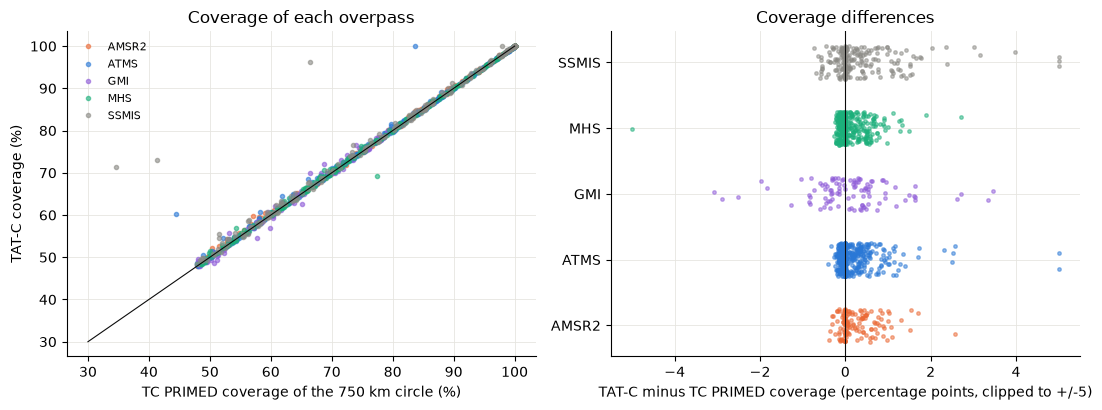

,n,median,5th percentile,95th percentile,max |x|
AMSR2,137.0,0.07,-0.19,1.03,2.57
ATMS,628.0,0.00,-0.15,0.83,16.34
GMI,101.0,0.17,-1.28,1.63,3.47
MHS,356.0,0.00,-0.19,0.74,8.21
SSMIS,211.0,0.04,-0.49,1.70,36.88


In [8]:
matched["coverage difference"] = (
    matched["TAT-C coverage (%)"] - matched["TC PRIMED coverage (%)"]
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
colors = {"ATMS": BLUE, "MHS": AQUA, "AMSR2": ORANGE, "GMI": PURPLE, "SSMIS": GRAY}
for sensor, g in matched.groupby("sensor"):
    axes[0].plot(
        g["TC PRIMED coverage (%)"],
        g["TAT-C coverage (%)"],
        "o",
        ms=3,
        alpha=0.6,
        color=colors[sensor],
        label=sensor,
    )
axes[0].plot([30, 100], [30, 100], color=INK, lw=0.8)
axes[0].set(
    xlabel="TC PRIMED coverage of the 750 km circle (%)",
    ylabel="TAT-C coverage (%)",
    title="Coverage of each overpass",
)
axes[0].legend(frameon=False, fontsize=8)
for k, (sensor, g) in enumerate(matched.groupby("sensor")):
    axes[1].plot(
        g["coverage difference"].clip(-5, 5),
        k + np.random.default_rng(0).uniform(-0.25, 0.25, len(g)),
        "o",
        ms=2.5,
        alpha=0.5,
        color=colors[sensor],
    )
axes[1].set_yticks(range(matched.sensor.nunique()), sorted(matched.sensor.unique()))
axes[1].axvline(0, color=INK, lw=0.8)
axes[1].set(
    xlabel="TAT-C minus TC PRIMED coverage (percentage points, clipped to +/-5)",
    title="Coverage differences",
)
fig.tight_layout()
plt.show()
pd.DataFrame(
    {
        sensor: summarize(g["coverage difference"])
        for sensor, g in matched.groupby("sensor")
    }
).T.round(2)

In [9]:
outliers = matched[matched["coverage difference"].abs() > 5]
outliers[
    [
        "storm",
        "platform",
        "TC PRIMED time",
        "TC PRIMED coverage (%)",
        "TAT-C coverage (%)",
    ]
].round({"TC PRIMED coverage (%)": 1, "TAT-C coverage (%)": 1})

,storm,platform,TC PRIMED time,TC PRIMED coverage (%),TAT-C coverage (%)
160,AL042025,F17,2025-08-11 19:18:10+00:00,34.6,71.5
203,AL042025,METOPB,2025-08-02 15:00:49+00:00,77.5,69.3
357,AL052025,F17,2025-08-15 21:36:27+00:00,66.4,96.3
597,AL052025,NPP,2025-08-12 16:27:54+00:00,44.4,60.2
630,AL052025,NPP,2025-08-26 13:57:27+00:00,83.7,100.0
982,AL092025,F18,2025-09-30 09:58:47+00:00,41.3,73.0


TAT-C's coverage matches TC PRIMED's to within a fraction of a percentage point:
* the median difference is within 0.2 points for every sensor; and
* 90% of the overpasses (5th to 95th percentile) differ by -1.3 to +1.7 points, with the largest spread for GMI.

Six overpasses differ by more than 5 points, and in all six TC PRIMED reports less coverage than TAT-C. TC PRIMED computes coverage from the swath it retains, which excludes scans and samples with missing geolocation (fill values; Section 2.2.2 of its documentation). An incomplete swath covers less of the circle than the full swath that TAT-C predicts. Three of these six overpasses are in TC PRIMED only through the 250 km criterion.

### Observation Times

The two sources define the time of an overpass differently:
* **TAT-C:** the time of the footprint that views most of the 750 km circle.
* **TC PRIMED:** the midpoint of the part of the granule within 20 deg of latitude and longitude of the storm.

These definitions need not coincide, so the times are compared only as a check.

In [10]:
matched["time difference (s)"] = (
    matched["TAT-C time"] - matched["TC PRIMED time"]
).dt.total_seconds()
times3 = {
    platform: summarize(g["time difference (s)"])
    for platform, g in matched.groupby("platform")
}
# GPM's overpasses by its orientation (from the attitude schedule)
gpm_overpasses = matched[matched.platform == "GPM"]
backward = np.array(
    [
        gpm_attitude.get_attitude(t.to_pydatetime()).yaw_angle == 180
        for t in gpm_overpasses["TC PRIMED time"]
    ]
)
times3["GPM, forward"] = summarize(gpm_overpasses["time difference (s)"][~backward])
times3["GPM, backward"] = summarize(gpm_overpasses["time difference (s)"][backward])
pd.DataFrame(times3).T.loc[[*PLATFORMS.index, "GPM, forward", "GPM, backward"]].round(1)

,n,median,5th percentile,95th percentile,max |x|
NPP,206.0,1.0,-24.0,30.8,94.0
NOAA20,213.0,3.0,-27.2,25.0,67.0
NOAA21,209.0,3.0,-23.0,24.6,64.0
METOPB,174.0,0.0,-30.0,27.0,43.0
METOPC,182.0,2.0,-29.0,27.9,64.0
GCOMW1,137.0,-30.0,-72.0,18.0,89.0
GPM,101.0,2.0,-78.0,68.0,126.0
F16,66.0,-31.0,-65.8,2.0,75.0
F17,76.0,-33.5,-89.5,0.8,220.0
F18,69.0,-27.0,-89.6,9.2,247.0


**Cross-track sounders.** The two times agree within 3 s (median) and 31 s (95th percentile). TC PRIMED's times are given to the nearest second.

**AMSR2 and SSMIS.** TAT-C's times are about 30 s earlier (median). Their arcs lie 850 to 900 km ahead of nadir at the center of the scan, but much less at its ends. The part of a granule within 20 deg of the storm ends when the arc's ends leave that region, so its midpoint is later than the time at which the arc's center sweeps across the storm.

**GMI.** GMI's arc is closer to nadir (about 520 km). Its median offset is -8.5 s when GPM flies forward and +8 s when it flies backward, when the arc trails nadir. Modeled as always flying forward, GPM's backward passes would be predicted about 2 minutes early: the arc would be about 1,040 km (about 140 s of flight) from where it really is. With the attitude schedule, the median offset of all of GPM's passes is 2 s.

The largest offsets (up to 4 minutes, for SSMIS) are again overpasses with incomplete swaths.

## Test 4: Sampling of Storms

An OSSE asks how often an observing system observes a feature. For each storm, the time between consecutive overpasses that meet TC PRIMED's criteria (by any of the 10 satellites) is compared three ways: as archived in TC PRIMED, as predicted by TAT-C, and as predicted without the three SSMIS. The overpasses of Hurricane Melissa (AL13), the strongest storm of the season, are shown as an example.

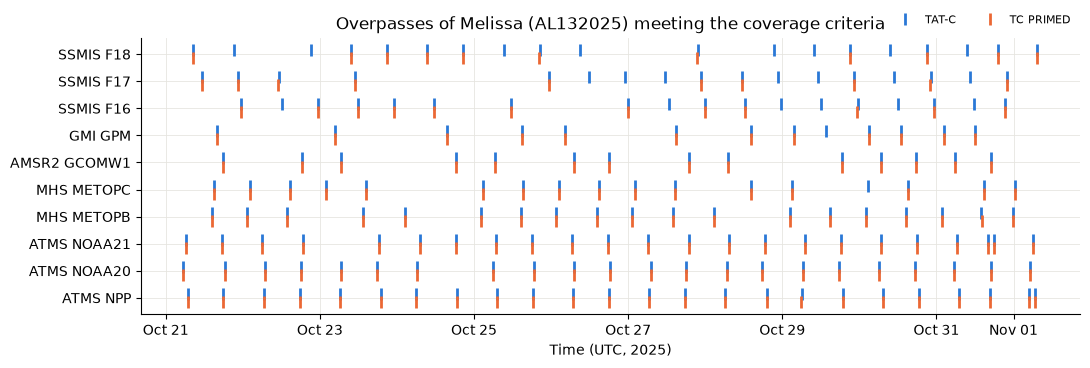

,gaps,median (h),5th percentile (h),95th percentile (h),max |x| (h)
TC PRIMED (archived overpasses),1420.0,0.84,0.13,4.72,7.65
TAT-C (all satellites),1678.0,0.83,0.12,3.85,5.67
TAT-C (without SSMIS),1224.0,0.82,0.10,6.85,8.45


In [11]:
STORM = "AL132025"
storm_name = "Melissa"
fig, ax = plt.subplots(figsize=(11, 3.8))
for k, platform in enumerate(PLATFORMS.index):
    tatc = included[(included.storm == STORM) & (included.platform == platform)]
    archived = matched[(matched.storm == STORM) & (matched.platform == platform)]
    ax.plot(
        tatc["pass"],
        np.full(len(tatc), k + 0.15),
        "|",
        ms=9,
        mew=2,
        color=BLUE,
        label="TAT-C" if k == 0 else None,
    )
    ax.plot(
        archived["TC PRIMED time"],
        np.full(len(archived), k - 0.15),
        "|",
        ms=9,
        mew=2,
        color=ORANGE,
        label="TC PRIMED" if k == 0 else None,
    )
ax.set_yticks(
    range(len(PLATFORMS)), [f"{PLATFORMS.sensor[p]} {p}" for p in PLATFORMS.index]
)
ax.set(
    title=f"Overpasses of {storm_name} ({STORM}) meeting the coverage criteria",
    xlabel="Time (UTC, 2025)",
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(
    frameon=False, fontsize=8, ncols=2, loc="upper right", bbox_to_anchor=(1, 1.12)
)
fig.tight_layout()
plt.show()


def gaps(times_by_storm):
    """Hours between consecutive overpasses of each storm (by any of the satellites)."""
    return np.concatenate(
        [
            np.diff(np.sort(t.to_numpy())).astype("timedelta64[s]").astype(float) / 3600
            for t in times_by_storm
        ]
    )


pd.DataFrame(
    {
        "TC PRIMED (archived overpasses)": summarize(
            gaps([g["TC PRIMED time"] for _, g in matched.groupby("storm")])
        ),
        "TAT-C (all satellites)": summarize(
            gaps([g["pass"] for _, g in included.groupby("storm")])
        ),
        "TAT-C (without SSMIS)": summarize(
            gaps(
                [
                    g["pass"]
                    for _, g in included[
                        ~included.platform.str.startswith("F")
                    ].groupby("storm")
                ]
            )
        ),
    }
).T.rename(columns=lambda c: f"{c} (h)" if c != "n" else "gaps").round(2)

The constellation observes a storm about every 50 minutes (a median gap of 0.83 h), whether archived or predicted. The longest gaps differ:

| Overpasses | 95th percentile of the gaps | Longest gap |
| --- | --- | --- |
| Predicted by TAT-C, all 10 satellites | 3.9 h | 5.7 h |
| Archived in TC PRIMED (many SSMIS overpasses missing) | 4.7 h | 7.7 h |
| Predicted by TAT-C, without SSMIS | 6.9 h | 8.5 h |

The three DMSP satellites, in different orbit planes from the other seven, fill the longest gaps between their passes. The gaps in the archive therefore follow from the availability of data, not from the constellation's geometry.

## Summary

| Test | Result |
| --- | --- |
| 1. Swaths | ATMS +/-52.7 deg (inertial frame) and MHS +/-49.4 deg (Earth-fixed, as Metop is yaw steered); AMSR2, GMI, and SSMIS cones of 47.6, 48.5, and 45.3 to 45.7 deg over sectors of +/-75.0, +/-75.7, and +/-70.8 deg (inertial); GPM flies backward in two of four periods, modeled with an `AttitudeSchedule` |
| 2. Overpasses (`collect_feature_observations`) | all 1,433 TC PRIMED overpasses predicted; 94% to 100% of the predicted passes are in TC PRIMED for the non-SSMIS sensors (12 passes missing from TC PRIMED are within 0.05 of a threshold, a few others fall in data gaps), and 43% to 49% for SSMIS (data availability) |
| 3. Coverage (`viewed_fraction`) | median difference within 0.2 percentage points for every sensor; 5th to 95th percentile -1.3 to +1.7 points; larger differences only where TC PRIMED's swath is incomplete; observation times within 3 s (median) for cross-track sounders, and 30 s apart for conical scanners from the definitions of time |
| 4. Sampling of storms | median gap between overpasses 0.83 h predicted and 0.84 h archived; longest gap 5.7 h predicted and 7.7 h archived (missing SSMIS data) |

**Feature observations.** With features that exist for a period of time (a storm's circle during a pass), `collect_feature_observations` reproduces a real archive's selection of overpasses one by one, and its coverage to a fraction of a percent. It does so for five sensors on 10 satellites over a season, from public element sets and swath geometry measured from the archive itself. TAT-C can therefore predict how constellations, including planned sensors, would observe storms in an OSSE.

**Capability and archives.** Most passes that TAT-C predicts but the archive lacks fall in gaps in the data, notably for SSMIS. TAT-C predicts what a constellation can observe, which an archive undercounts wherever data are missing. Comparing the two identifies the gaps.

**Attitude.** The swaths depend on each spacecraft's attitude: the inertial velocity frame for the satellites that are not yaw steered, the Earth-fixed frame for Metop, and GPM's yaw flips. The flips are recovered from the observations and modeled with an `AttitudeSchedule`, which moves GMI's observation times by about 2 minutes in the periods when GPM flies backward.

**Limitations.** TAT-C predicts complete swaths; missing scans or samples reduce the coverage of a few archived overpasses. The element sets are a public history with about 3.6 element sets per day per satellite. A storm's circle is centered at its position at the closest approach, which is within a few kilometers of its position at TC PRIMED's time of observation.